Churn label distribution:
churn_label
0    50
1    50
Name: count, dtype: int64
churn_label
0    0.5
1    0.5
Name: proportion, dtype: float64

Model Performance
Accuracy : 0.85
Precision: 0.82
Recall   : 0.90
F1 Score : 0.86

Classification Report
              precision    recall  f1-score   support

           0       0.89      0.80      0.84        10
           1       0.82      0.90      0.86        10

    accuracy                           0.85        20
   macro avg       0.85      0.85      0.85        20
weighted avg       0.85      0.85      0.85        20


Confusion Matrix
[[8 2]
 [1 9]]

Top 10 Important Features:
                        Feature  Importance
6            last_purchase_days    0.108970
11         repeat_purchase_rate    0.107651
3            purchase_frequency    0.077943
2                spending_score    0.075841
4               avg_order_value    0.073843
9   customer_satisfaction_score    0.073487
5               total_purchases    0.068721
7       cus

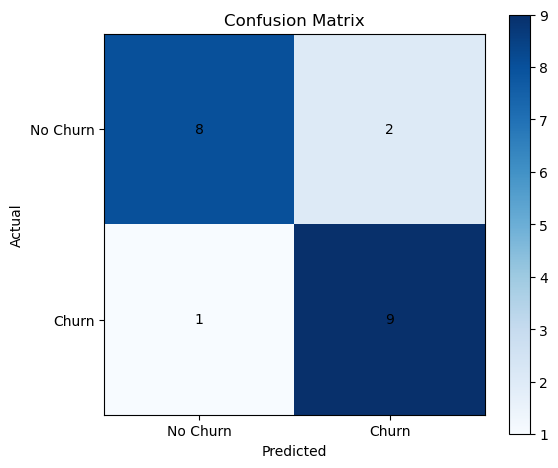

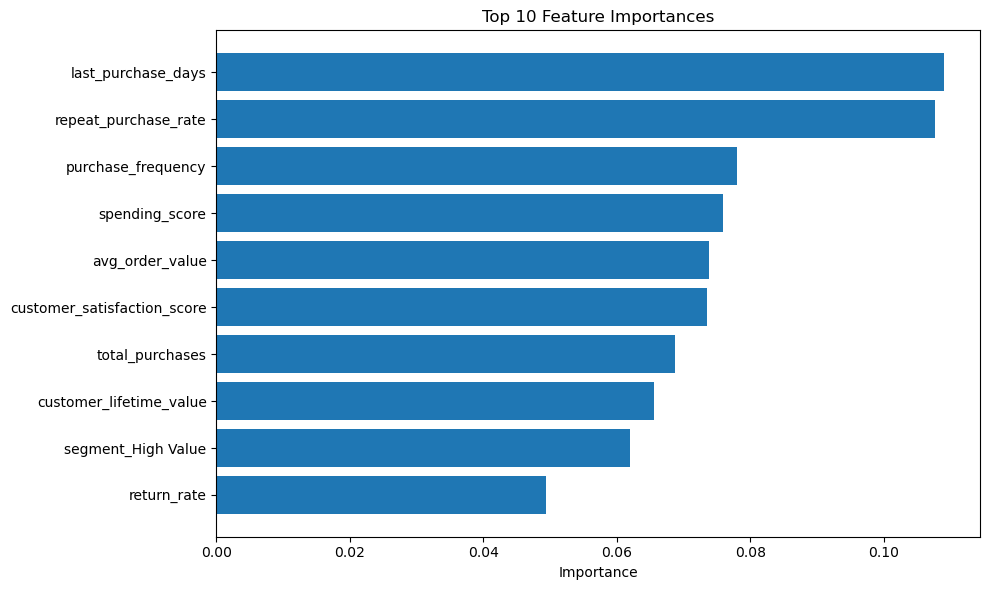


Saved dataset as customers_with_churn_label.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier

# -----------------------------
# 1. LOAD DATA
# -----------------------------
df = pd.read_csv("customers.csv")
df.columns = df.columns.str.strip()

# -----------------------------
# 2. CREATE SYNTHETIC CHURN LABEL
# -----------------------------
np.random.seed(42)

risk_score = (
    (df["last_purchase_days"] / df["last_purchase_days"].max()) * 0.4 +
    (1 - df["repeat_purchase_rate"]) * 0.3 +
    (1 - df["customer_satisfaction_score"] / 5) * 0.2 +
    (1 - df["newsletter_subscribed"].map({"Yes": 1, "No": 0})) * 0.1
)

noise = np.random.normal(0, 0.05, len(df))
final_score = risk_score + noise
threshold = final_score.median()

df["churn_label"] = (final_score > threshold).astype(int)

print("Churn label distribution:")
print(df["churn_label"].value_counts())
print(df["churn_label"].value_counts(normalize=True))

# -----------------------------
# 3. FEATURES / TARGET
# -----------------------------
target_col = "churn_label"
drop_cols = ["customer_id", target_col]

X = df.drop(columns=drop_cols)
y = df[target_col]

# -----------------------------
# 4. COLUMN TYPES
# -----------------------------
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

# -----------------------------
# 5. PREPROCESSING
# -----------------------------
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# -----------------------------
# 6. MODEL
# -----------------------------
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# -----------------------------
# 7. TRAIN / TEST SPLIT
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 8. TRAIN MODEL
# -----------------------------
model.fit(X_train, y_train)

# -----------------------------
# 9. PREDICTIONS
# -----------------------------
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# -----------------------------
# 10. EVALUATION
# -----------------------------
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
cm = confusion_matrix(y_test, y_pred)

print("\nModel Performance")
print(f"Accuracy : {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall   : {recall:.2f}")
print(f"F1 Score : {f1:.2f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix")
print(cm)

# -----------------------------
# 11. FEATURE IMPORTANCE
# -----------------------------
# Get one-hot feature names
ohe = model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
cat_feature_names = ohe.get_feature_names_out(categorical_cols)
all_feature_names = numeric_cols + cat_feature_names.tolist()

importances = model.named_steps["classifier"].feature_importances_
feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("\nTop 10 Important Features:")
print(feature_importance_df.head(10))

# -----------------------------
# 12. PLOT CONFUSION MATRIX
# -----------------------------
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center", color="black")

plt.xticks([0, 1], ["No Churn", "Churn"])
plt.yticks([0, 1], ["No Churn", "Churn"])
plt.tight_layout()
plt.show()

# -----------------------------
# 13. PLOT FEATURE IMPORTANCE
# -----------------------------
top_features = feature_importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# -----------------------------
# 14. SAVE UPDATED DATASET
# -----------------------------
df.to_csv("customers_with_churn_label.csv", index=False)
print("\nSaved dataset as customers_with_churn_label.csv")